<a href="https://colab.research.google.com/github/syifahumaira17/simuteh-2330511079/blob/main/P6_morfologi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone https://github.com/syifahumaira17/simuteh-2330511079.git

Cloning into 'simuteh-2330511079'...
remote: Enumerating objects: 322, done.
remote: Counting objects: 100% (84/84), done.
remote: Compressing objects: 100% (75/75), done.
remote: Total 322 (delta 27), reused 46 (delta 8), pack-reused 238 (from 1)
Receiving objects: 100% (322/322), 74.27 MiB | 23.39 MiB/s, done.
Resolving deltas: 100% (38/38), done.


In [2]:
%cd /content/simuteh-2330511079

/content/simuteh-2330511079


In [3]:
!ls

data  hasil  laporan  notebook	README.md  requirements.txt  src


In [4]:
!ls hasil
!ls src
!ls data/sintetis

b1_bgr_rgb.png			b5_perbandingan_citra_sehat.png
b1_pipeline.png			b5_perbandingan_kb.png
b3_tabel_kb_metode.csv		b5_pipeline_final.png
b4_crop_bercak_median.png	b5_ringkasan_citra_sehat.csv
b4_crop_median.png		b5_ringkasan_kb.csv
b4_eksperimen_median.csv	b5_uji_20_citra_sehat.csv
b4_grafik_di_median.png		p5_canny_persentil.csv
b4_grafik_kb_median.png		p5_canny_sigma_ambang.csv
b4_pengujian_kernel_median.csv	p5_f1_kondisi.png
b4_ringkasan_kernel_median.csv	p5_tabel7_canny.csv
b4_tabel_penapis.csv		p5_tabel_tepi.csv
b4_urutan_denoise_sharpen.png	param_praproses.json
b5_kb_40_citra.csv
buat_dataset_sintetis.py  praproses.py	utils_cv.py  utils_tepi.py
bersih	citra  label.csv  mask_bercak  mask_daun


In [5]:
import sys, json
sys.path.append("src")

import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

PARAM = json.load(open("hasil/param_praproses.json"))
label = pd.read_csv("data/sintetis/label.csv")

def muat(nama):
    img = baca(f"data/sintetis/citra/{nama}")
    md = cv2.imread(f"data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)

print("Persiapan P6 berhasil!")
print("Jumlah data:", len(label))
print("Ukuran citra:", img.shape)

Persiapan P6 berhasil!
Jumlah data: 60
Ukuran citra: (480, 640, 3)


In [6]:
def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

print("Fungsi Canny berhasil disiapkan!")

Fungsi Canny berhasil disiapkan!


         citra  IoU daun awal  komponen bercak awal  komponen acuan IoU bercak awal
0  teh_041.png          0.992                   162               9           0.427
1  teh_021.png          0.998                   194               3           0.145
2  teh_011.png          0.998                   139               0               -


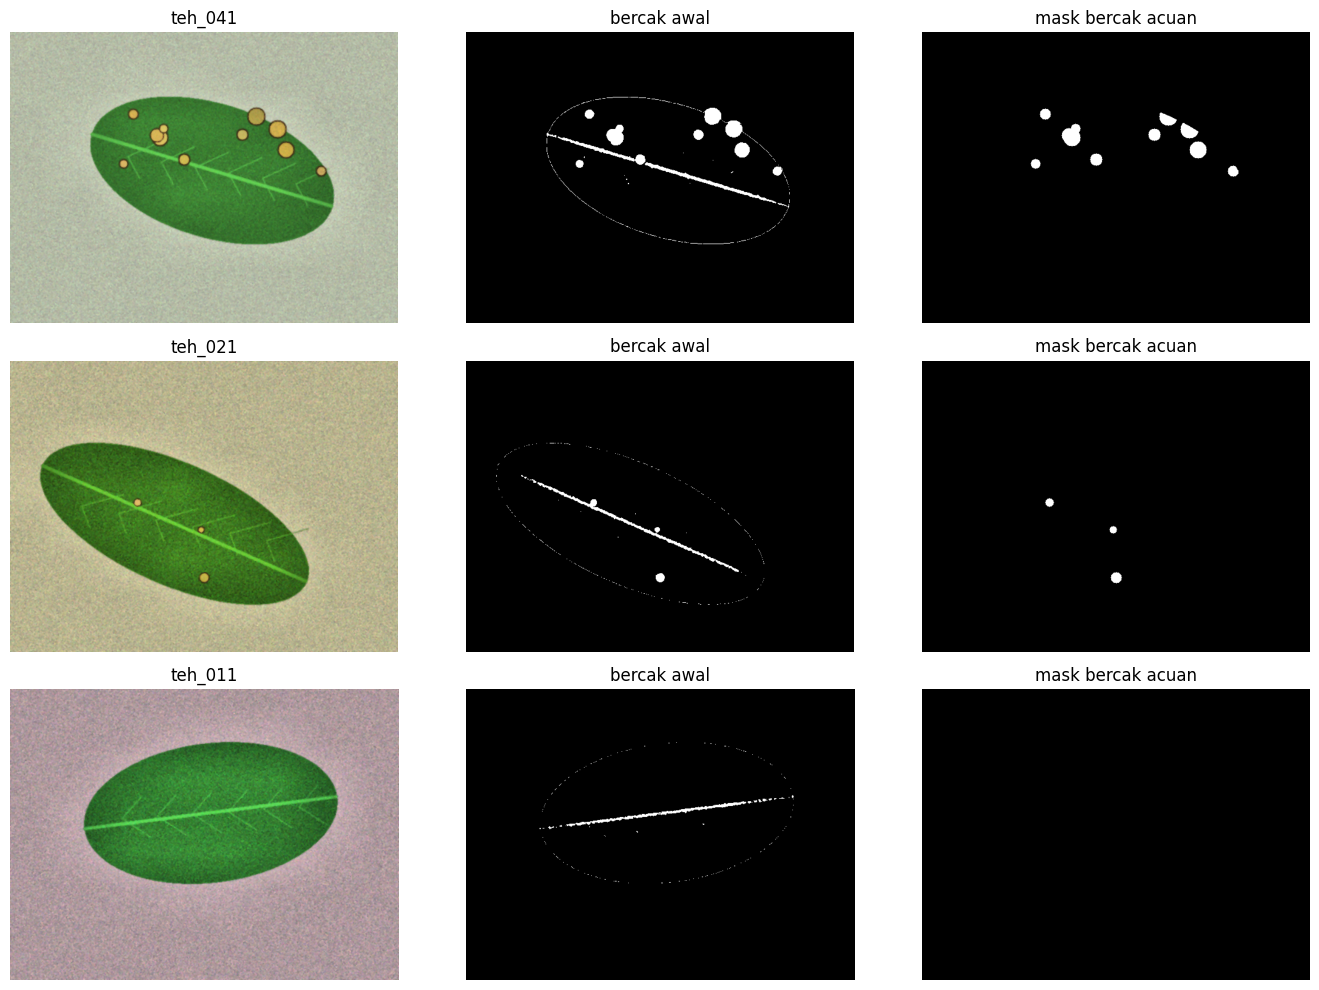

In [7]:
def jumlah_komponen(m, konek=8):
    return cv2.connectedComponents(
        (m > 0).astype(np.uint8),
        connectivity=konek
    )[0] - 1

baris, panel, judul = [], [], []

for nama in ["teh_041.png", "teh_021.png", "teh_011.png"]:
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)

    m_daun = mask_daun_awal(pra_)
    b0 = bercak_awal(pra_, m_daun, kanal=2, k=4.0)

    baris.append([
        nama,
        round(iou(m_daun, md), 3),
        jumlah_komponen(b0),
        jumlah_komponen(mb),
        round(iou(b0, mb), 3) if mb.any() else "-"
    ])

    panel += [pra_, b0, mb]
    judul += [nama[:7], "bercak awal", "mask bercak acuan"]

print(pd.DataFrame(
    baris,
    columns=[
        "citra",
        "IoU daun awal",
        "komponen bercak awal",
        "komponen acuan",
        "IoU bercak awal"
    ]
))

tampil(panel, judul, baris=3, ukuran=(14, 10))

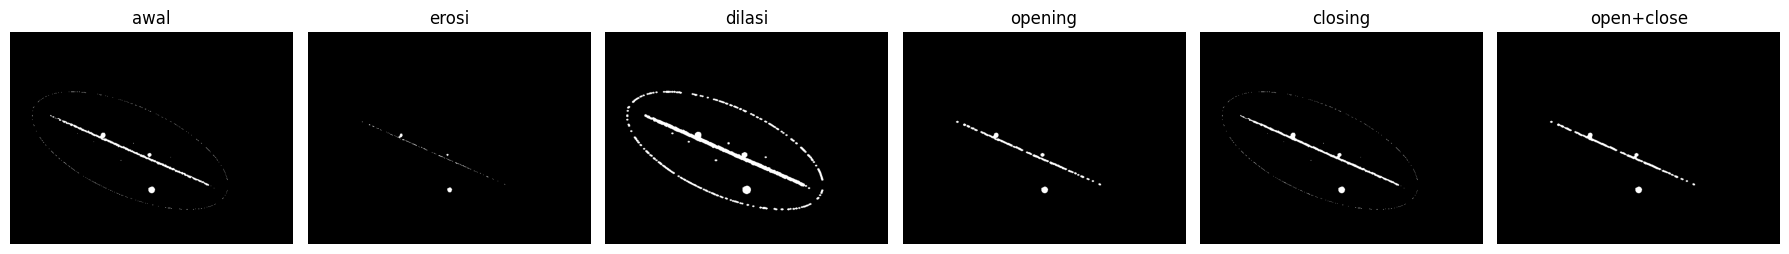

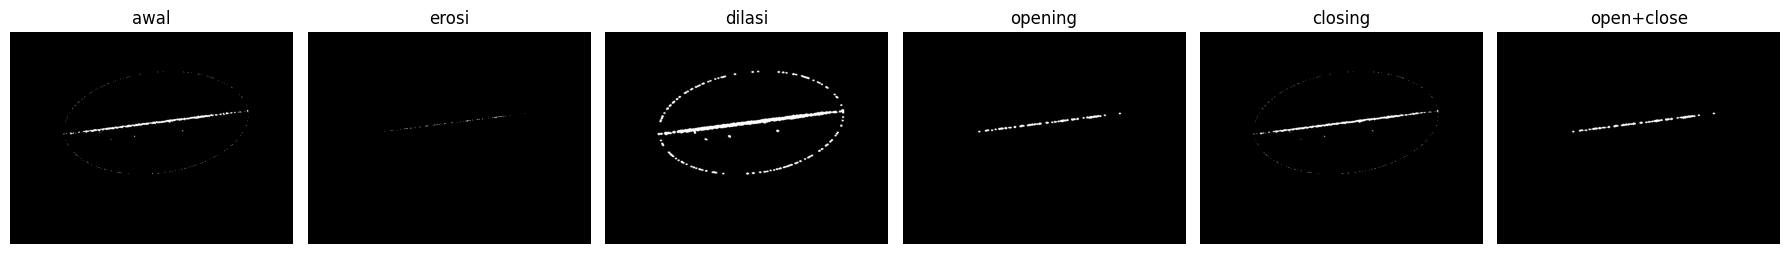

          citra     operasi  komponen  piksel    IoU
0   teh_021.png        awal       194    2284  0.145
1   teh_021.png       erosi        58     348  0.233
2   teh_021.png      dilasi        65    7064  0.073
3   teh_021.png     opening        17    1593  0.195
4   teh_021.png     closing       187    2413  0.144
5   teh_021.png  open+close         8    1680  0.197
6   teh_011.png        awal       139    1601      -
7   teh_011.png       erosi        42     116      -
8   teh_011.png      dilasi        68    5309      -
9   teh_011.png     opening        20     896      -
10  teh_011.png     closing       130    1679      -
11  teh_011.png  open+close        12     927      -


In [8]:
SE = lambda k, bentuk=cv2.MORPH_ELLIPSE: cv2.getStructuringElement(bentuk, (k, k))

def operasi(b, se):
    return {
        "awal": b,
        "erosi": cv2.erode(b, se),
        "dilasi": cv2.dilate(b, se),
        "opening": cv2.morphologyEx(b, cv2.MORPH_OPEN, se),
        "closing": cv2.morphologyEx(b, cv2.MORPH_CLOSE, se),
        "open+close": cv2.morphologyEx(
            cv2.morphologyEx(b, cv2.MORPH_OPEN, se),
            cv2.MORPH_CLOSE, se
        )
    }

baris = []

for nama in ["teh_021.png", "teh_011.png"]:
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    b0 = bercak_awal(pra_, mask_daun_awal(pra_))
    hasil = operasi(b0, SE(5))

    for nm, m in hasil.items():
        baris.append([
            nama,
            nm,
            jumlah_komponen(m),
            int((m > 0).sum()),
            round(iou(m, mb), 3) if mb.any() else "-"
        ])

    tampil(list(hasil.values()), list(hasil.keys()), ukuran=(18, 3))
    plt.show()

print(pd.DataFrame(
    baris,
    columns=["citra", "operasi", "komponen", "piksel", "IoU"]
))

In [9]:
bentuk = {
    "persegi": cv2.MORPH_RECT,
    "elips": cv2.MORPH_ELLIPSE,
    "silang": cv2.MORPH_CROSS
}

baris = []

for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    n_acuan = jumlah_komponen(mb)

    for k in [3, 4, 6]:
        b0 = bercak_awal(pra_, m_daun, k=k)

        for nb, kb in bentuk.items():
            for uk in [3, 5, 7]:
                se = SE(uk, kb)

                m = cv2.morphologyEx(
                    cv2.morphologyEx(b0, cv2.MORPH_OPEN, se),
                    cv2.MORPH_CLOSE, se
                )

                baris.append([
                    d.kelas,
                    k,
                    nb,
                    uk,
                    abs(jumlah_komponen(m) - n_acuan),
                    iou(m, mb) if mb.any() else np.nan
                ])

eks = pd.DataFrame(
    baris,
    columns=["kelas", "k", "bentuk", "ukuran", "galat_jumlah", "IoU"]
)

print(eks.pivot_table(
    index=["k", "bentuk", "ukuran"],
    columns="kelas",
    values=["galat_jumlah", "IoU"]
).round(2))

eks.to_csv("hasil/p6_eksperimen_se.csv", index=False)

print("\nPengujian selesai!")
print("Jumlah hasil pengujian:", len(eks))
print("CSV tersimpan di hasil/p6_eksperimen_se.csv")

                   IoU        galat_jumlah              
kelas            berat ringan        berat ringan  sehat
k bentuk  ukuran                                        
3 elips   3       0.59   0.15        26.20  17.35  25.55
          5       0.64   0.21         3.90   3.85   3.15
          7       0.67   0.43         1.80   1.85   2.60
  persegi 3       0.61   0.16         8.50   7.75   8.25
          5       0.65   0.31         1.65   4.00   3.90
          7       0.66   0.44         0.90   0.65   0.10
  silang  3       0.59   0.15        26.20  17.35  25.55
          5       0.64   0.20         7.30   7.15   5.75
          7       0.68   0.37         3.50   4.50   5.00
4 elips   3       0.64   0.25        14.95  10.90  14.15
          5       0.64   0.37         1.40   3.50   3.75
          7       0.65   0.51         0.90   0.20   1.25
  persegi 3       0.64   0.28         5.60   6.70   5.60
          5       0.65   0.46         1.05   1.25   1.90
          7       0.62   0.39  

In [10]:
baris = []

for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)

    m_daun = mask_daun_awal(pra_)

    grad = cv2.morphologyEx(
        m_daun,
        cv2.MORPH_GRADIENT,
        SE(3)
    )

    canny = tepi_canny(
        cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)
    )

    ad = tepi_acuan(md)

    baris.append([
        d.kondisi_cahaya,
        skor_tepi(grad, ad)[2],
        skor_tepi(canny, ad)[2]
    ])

print(
    pd.DataFrame(
        baris,
        columns=[
            "kondisi",
            "F1 gradien morfologi",
            "F1 Canny"
        ]
    )
    .groupby("kondisi")
    .mean()
    .round(3)
)

                F1 gradien morfologi  F1 Canny
kondisi                                       
bayangan                       0.871     0.703
gelap                          0.989     0.693
kontras_rendah                 0.193     0.899
normal                         0.985     0.685
terang                         0.928     0.687


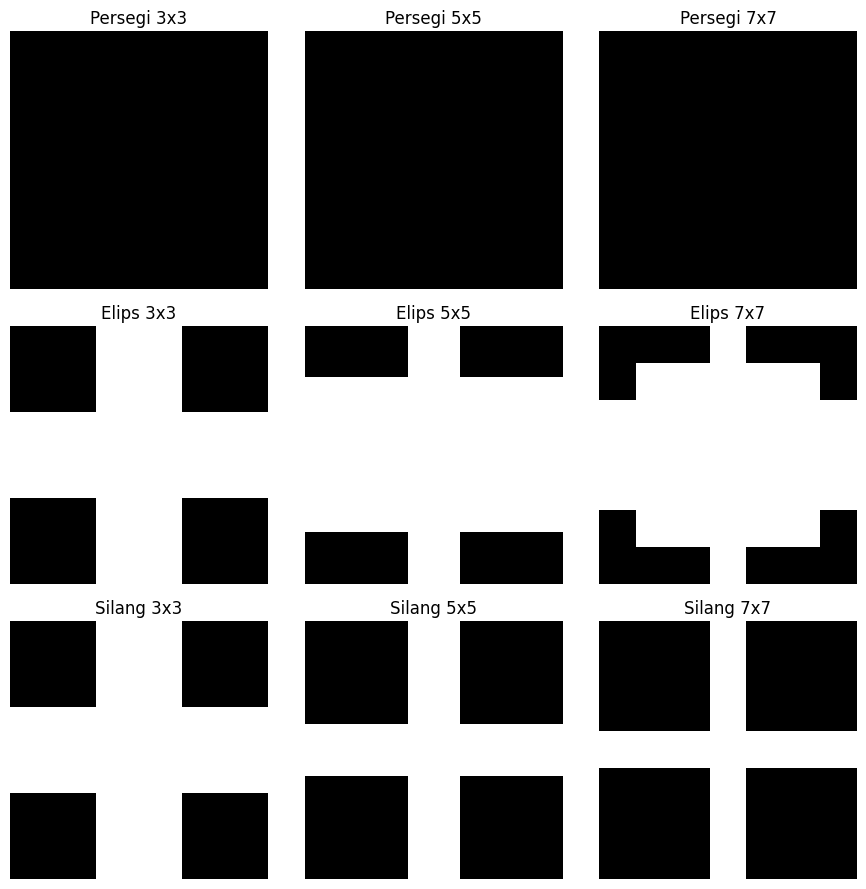

In [11]:
bentuk_se = {
    "Persegi": cv2.MORPH_RECT,
    "Elips": cv2.MORPH_ELLIPSE,
    "Silang": cv2.MORPH_CROSS
}

fig, axes = plt.subplots(3, 3, figsize=(9, 9))

for i, (nama, bentuk) in enumerate(bentuk_se.items()):
    for j, ukuran in enumerate([3, 5, 7]):
        se = cv2.getStructuringElement(
            bentuk, (ukuran, ukuran)
        )

        axes[i, j].imshow(se, cmap="gray")
        axes[i, j].set_title(f"{nama} {ukuran}x{ukuran}")
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

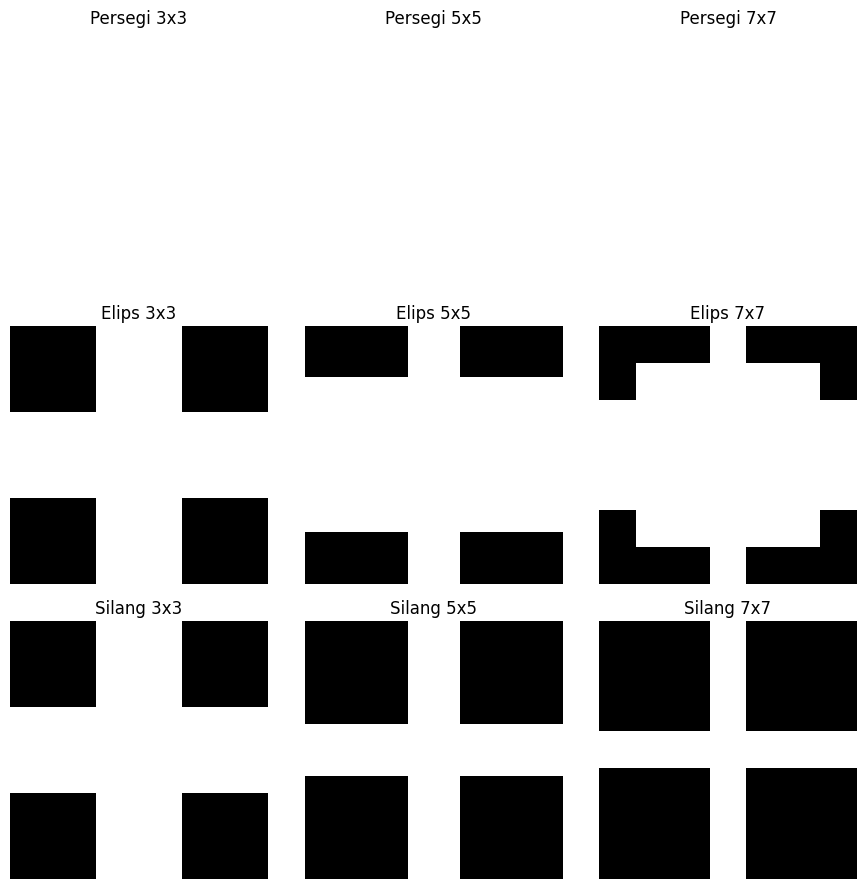

In [12]:
bentuk_se = {
    "Persegi": cv2.MORPH_RECT,
    "Elips": cv2.MORPH_ELLIPSE,
    "Silang": cv2.MORPH_CROSS
}

fig, axes = plt.subplots(3, 3, figsize=(9, 9))

for i, (nama, bentuk) in enumerate(bentuk_se.items()):
    for j, ukuran in enumerate([3, 5, 7]):
        se = cv2.getStructuringElement(
            bentuk, (ukuran, ukuran)
        )

        axes[i, j].imshow(
            se, cmap="gray", vmin=0, vmax=1
        )
        axes[i, j].set_title(f"{nama} {ukuran}x{ukuran}")
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

In [13]:
!ls hasil/p6_eksperimen_se.csv
!git status

hasil/p6_eksperimen_se.csv
On branch main
Your branch is up to date with 'origin/main'.

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	hasil/p6_eksperimen_se.csv

nothing added to commit but untracked files present (use "git add" to track)
